# Experiments to check the effect of the lengthscale parameter. No obstacle. 

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.colors import Normalize
from covderivatives2D import AnalyticalSqExpdiff2D
from matrices import CovM, Umat 

Importing covderivatives2D.py
Importing covderivatives.py


In [2]:
# Constants
PI = np.pi
seed = 20
np.random.seed(seed)                                        # Reproducibility

# user inputs
xl = 0; xr = 5
yd = 0; yu = 5
xinf = 0                                                    # x position of infinity
nobs = 5                                                    # Observed velocity/potential function values (before the obstacle)
nrandobs = 3                                                # Random observations in the domain
nd = 10                                                     # Collocation points in the domain (Continuity equtaion = Laplacian zero).
npred = 20                                                  # discretization for prediction points.
IMGPATH = r'IMAGES/'                                        # Image path

# Kernel hyperparameters
sigma = 1.0
theta = 1.0                                                 # set kernel parameters here
kwargs = dict(sigma = sigma, theta = theta)                 # dict. of kernel params
vinfx: float = 1.0                                          # Velocity_x at infinity
vinfy: float = 0                                            # velocity_y at infinity 

# Kernel differentiation function 
DiffKernel = lambda x, y, xindex, yindex, **kwargs: AnalyticalSqExpdiff2D(x, y,
                                                                          xindex, yindex,
                                                                          **kwargs)


In [3]:
# utility functions

# K inverse function
def fnKinv(K):
    I = np.eye(K.shape[0])
    nugget  = 1e-10; nI = nugget*I
    Kinv = np.linalg.solve(K+nI, I)
    return Kinv

# Simple Kriging without cross covariances

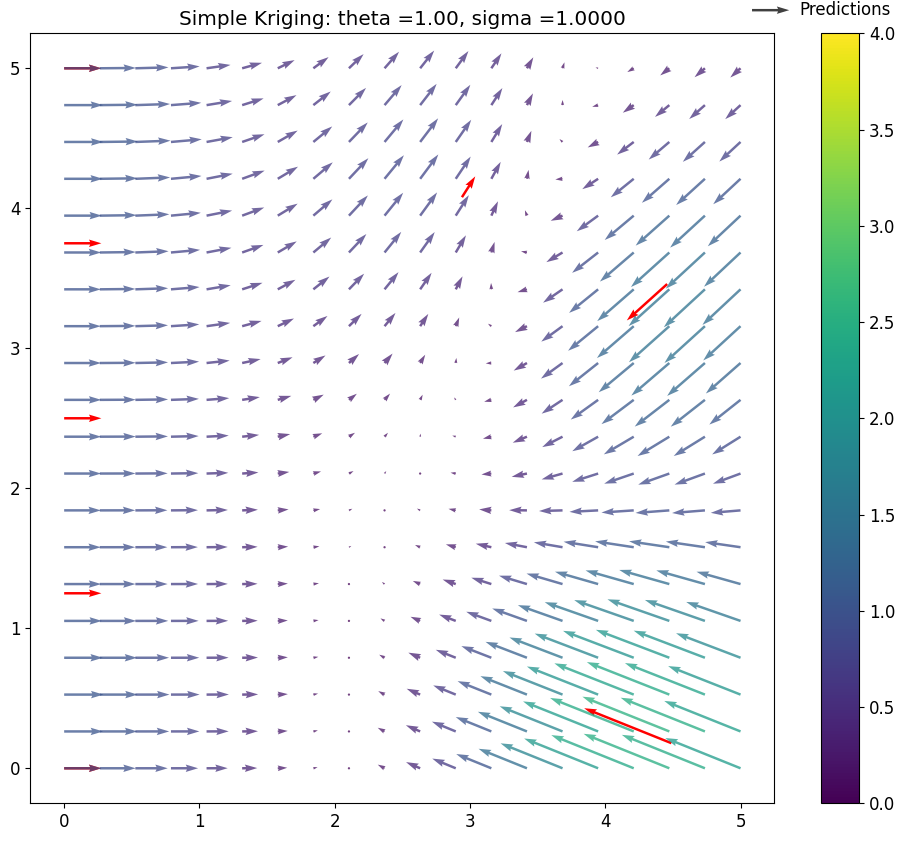

In [4]:
# This is NOT using the extended design space. We use the kronecker product to perform simple Kriging. 
# Observation locations. Derivative orders left zero.
Obs = np.zeros((nobs + nrandobs, 2, 2))                     # observation locations: NUM X COORDS/DERIVATIVE ORDER X DIM
xvals = xl + xinf + np.zeros(nobs)                          # observation locations at -infinity (x-coordinates)
yvals = np.linspace(yd, yu, nobs)                           # observation locations at -infinity (y-coordinates)
Obs[:nobs, 0, 0] = xvals; Obs[:nobs, 0, 1] = yvals          
Obs[nobs:nobs + nrandobs, 0, 0] = np.random.uniform(xl, xr, nrandobs)   # Random observation locations
Obs[nobs:nobs + nrandobs, 0, 1] = np.random.uniform(yd, yu, nrandobs)   # Random observation locations

# Observed velocities 
vobs = np.zeros(2 * (nobs + nrandobs))
vobs[:nobs] = vinfx; vobs[nobs:nobs+nrandobs] = np.random.standard_normal(nrandobs)
vobs[nobs+nrandobs:2*nobs+nrandobs] = vinfy; vobs[2*nobs+nrandobs:] = np.random.standard_normal(nrandobs) 

# Prediction points
xvals = np.linspace(xl, xr, npred)                          # prediction locations x-components
yvals = np.linspace(yd, yu, npred)                          # prediction locations y-components
xvals, yvals = np.meshgrid(xvals, yvals)
Pred = np.zeros((npred**2, 2, 2))                           # Initializing the prediction array
Pred[:npred**2, 0, 0] = xvals.flatten();
Pred[:npred**2, 0, 1] = yvals.flatten();

# Matrix K
K = CovM(Obs, kernel=DiffKernel, **kwargs)
Kkron = np.kron(np.eye(2), K)                               # Extending the matrix to include both vx and vy components assuming independence. 
Kkroninv = fnKinv(Kkron)                                    # Invert the matrix.
# Matrix H 
H = CovM(Obs, Pred, kernel=DiffKernel, **kwargs)
Hkron = np.kron(np.eye(2), H)

# final predictions
vhatkron = Hkron.T @ Kkroninv @ vobs 
vxhat = vhatkron[:npred**2]; vyhat = vhatkron[npred**2:]  

# Visualization 
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})       
widf = 1.5
plt.figure(figsize = (12,10))
plt.cla()
quiverkwargs = dict(scale = 1/0.05, width =(xr - xl)/(widf*1e3), pivot = 'tail')
Q1 = plt.quiver(Obs[:nobs+nrandobs, 0, 0], Obs[:nobs+nrandobs, 0, 1],
                vobs[:nobs+nrandobs], vobs[nobs+nrandobs:],
                color = 'red', alpha = 1,
                **quiverkwargs) 
Q2 = plt.quiver(Pred[:npred**2, 0, 0], Pred[:npred**2, 0, 1],
                vxhat, vyhat,
                np.hypot(vxhat, vyhat), 
                alpha = 0.75,
                **quiverkwargs)
plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
cnorm = Normalize(vmin = 0.0, vmax = 4.0)                     # To normalize the true values and scaling them to 0.0 --> 0.2 for the colorbar
plt.colorbar(cm.ScalarMappable(norm=cnorm), ax = plt.gca())
plt.clim(0.0, 4.0)      
# plt.colorbar()
plt.title(f'Simple Kriging: {theta =:.2f}, {sigma =:.4f}')
plt.show()


# Simple Kriging in the extended design space (with vx-vy cross-covariances)

Initialize the observation vector. (NUM X COORDS/DERIVATIVE ORDERS X [x, y]/[xindex, yindex])

In [5]:
# Using the same observation locations as before.
Obs_loc = Obs[:, 0, :]                                      # storing the observation locations.
Obs = np.zeros((2 * (nobs + nrandobs), 2, 2))
Obs[:nobs+nrandobs,1,0] = 1                                 # m = (1,0) indicating vx.
Obs[:nobs+nrandobs,0,:] = Obs_loc                           # vx observation locations
Obs[nobs+nrandobs:,0,:] = Obs[:nobs+nrandobs,0,:]           # Same locations for vx and vy components.
Obs[nobs+nrandobs:,1,1] = 1                                 # m = (0,1) indicating vy.

Initializing the prediction vector. 

In [6]:
# Prediction points
xvals = np.linspace(xl, xr, npred)                          # prediction locations x-components
yvals = np.linspace(yd, yu, npred)                          # prediction locations y-components
xvals, yvals = np.meshgrid(xvals, yvals)
Pred = np.zeros((2*npred**2, 2, 2))                         # Initializing the prediction array
Pred[:npred**2, 0, 0] = xvals.flatten();                    # vxhat locations
Pred[:npred**2, 0, 1] = yvals.flatten();                    
Pred[:npred**2, 1, 0] = 1                                   # m = (1,0)
Pred[npred**2:, 0, :] = Pred[:npred**2, 0, :]               # same locations for vyhat
Pred[npred**2:, 1, 1] = 1                                   # m = (0,1)

Creating the covariance matrices. Simple Kriging in the extended design space.

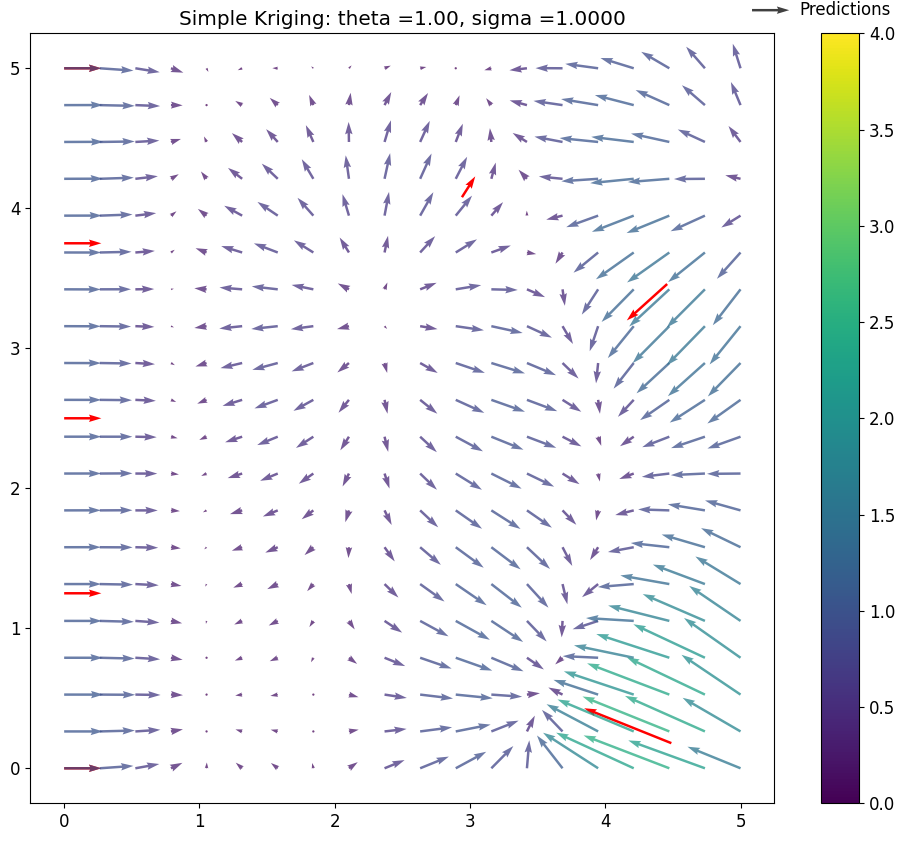

In [7]:
# Matrix K
theta = 1.0
sigma = 1.0
params = dict(theta = theta, sigma = sigma)

K = CovM(Obs, kernel = DiffKernel, **params)
H = CovM(Obs, Pred, kernel = DiffKernel, **params)

# Final predictions
I = np.eye(K.shape[0])
nugget  = 1e-10; nI = nugget*I
Kinv = np.linalg.solve(K+nI, I)
vhat = H.T @ Kinv @ vobs
vxhat = vhat[:npred**2]; 
vyhat = vhat[npred**2:];

# Visualization 
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})       
widf = 1.5
plt.figure(figsize = (12,10))
plt.cla()
quiverkwargs = dict(scale = 1/0.05, width =(xr - xl)/(widf*1e3), pivot = 'tail')
Q1 = plt.quiver(Obs[:nobs+nrandobs, 0, 0], Obs[:nobs+nrandobs, 0, 1],
                vobs[:nobs+nrandobs], vobs[nobs+nrandobs:],
                color = 'red', alpha = 1,
                **quiverkwargs) 
Q2 = plt.quiver(Pred[:npred**2, 0, 0], Pred[:npred**2, 0, 1],
                vxhat, vyhat,
                np.hypot(vxhat, vyhat), 
                alpha = 0.75,
                **quiverkwargs)
plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
# cnorm = Normalize(vmin = 0.0, vmax = 4.0)                     # To normalize the true values and scaling them to 0.0 --> 0.2 for the colorbar
plt.clim(0.0, 4.0)      
plt.colorbar(cm.ScalarMappable(norm=cnorm), ax = plt.gca())

plt.title(f'Simple Kriging: {theta =:.2f}, {sigma =:.4f}')
plt.show()

The effect of varying lengthscale param: $\theta = 0.5$, $\theta = 2$ and $\theta = 5$. 

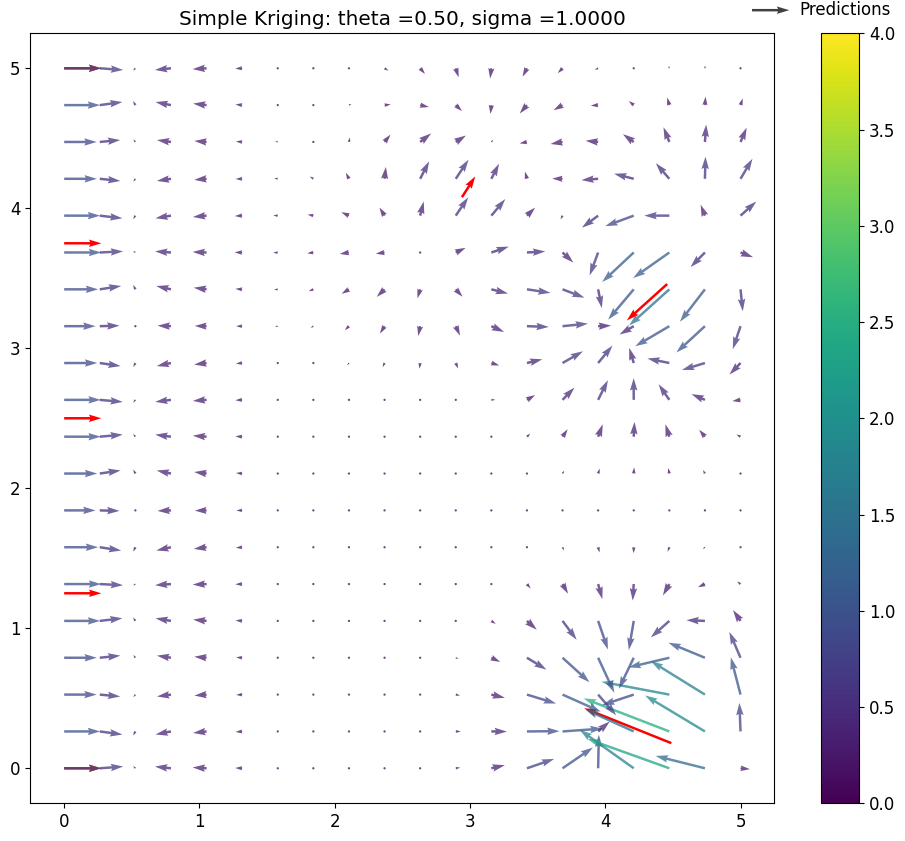

In [8]:
# kernel params
theta = 0.5
sigma = 1.0
params = dict(theta = theta, sigma = sigma)

K = CovM(Obs, kernel = DiffKernel, **params)
H = CovM(Obs, Pred, kernel = DiffKernel, **params)

# Final predictions
Kinv = fnKinv(K)
vhat = H.T @ Kinv @ vobs
vxhat = vhat[:npred**2]; 
vyhat = vhat[npred**2:];

# Visualization 
def visualize(vxhat, vyhat):
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12})       
    widf = 1.5
    plt.figure(figsize = (12,10))
    plt.cla()
    quiverkwargs = dict(scale = 1/0.05, width =(xr - xl)/(widf*1e3), pivot = 'tail')
    Q1 = plt.quiver(Obs[:nobs+nrandobs, 0, 0], Obs[:nobs+nrandobs, 0, 1],
                    vobs[:nobs+nrandobs], vobs[nobs+nrandobs:],
                    color = 'red', alpha = 1,
                    **quiverkwargs) 
    Q2 = plt.quiver(Pred[:npred**2, 0, 0], Pred[:npred**2, 0, 1],
                    vxhat, vyhat,
                    np.hypot(vxhat, vyhat), 
                    alpha = 0.75,
                    **quiverkwargs)
    plt.quiverkey(Q1, 1.02, 1.05, 1, label='Observations', labelpos = 'E')
    plt.quiverkey(Q2, 1.02, 1.03, 1, label='Predictions', labelpos = 'E')
    # plt.colorbar()
    plt.clim(0.0, 4.0)      
    plt.colorbar(cm.ScalarMappable(norm=cnorm), ax = plt.gca())
    
    plt.title(f'Simple Kriging: {theta =:.2f}, {sigma =:.4f}')
    plt.show()

# Visualization
visualize(vxhat, vyhat)


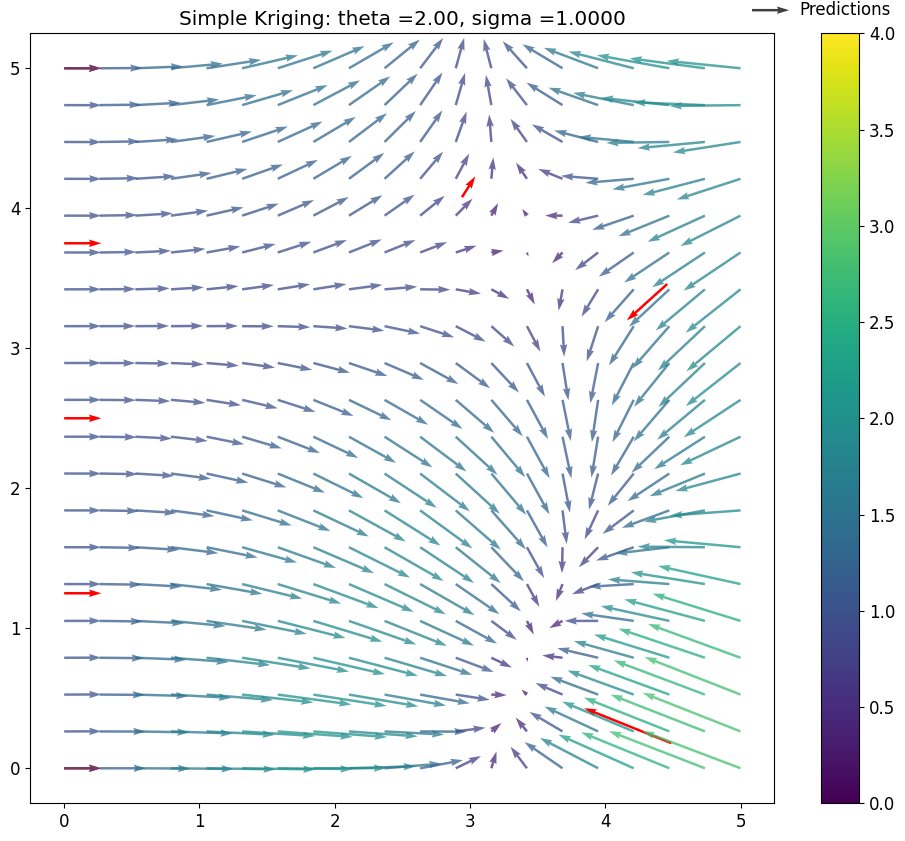

In [9]:
# kernel params
theta = 2.0
sigma = 1.0
params = dict(theta = theta, sigma = sigma)

K = CovM(Obs, kernel = DiffKernel, **params)
H = CovM(Obs, Pred, kernel = DiffKernel, **params)

# Final predictions
Kinv = fnKinv(K)
vhat = H.T @ Kinv @ vobs
vxhat = vhat[:npred**2]; 
vyhat = vhat[npred**2:];

# Visualization
visualize(vxhat, vyhat)


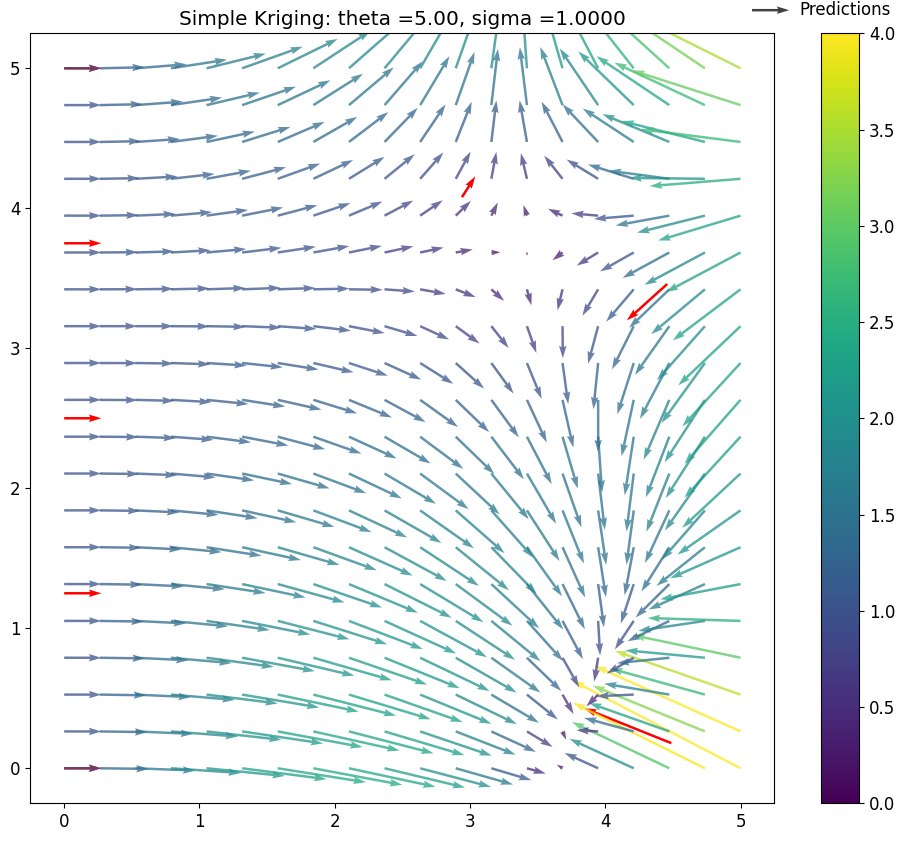

In [10]:
# kernel params
theta = 5.0
sigma = 1.0
params = dict(theta = theta, sigma = sigma)

K = CovM(Obs, kernel = DiffKernel, **params)
H = CovM(Obs, Pred, kernel = DiffKernel, **params)

# Final predictions
Kinv = fnKinv(K)
vhat = H.T @ Kinv @ vobs
vxhat = vhat[:npred**2]; 
vyhat = vhat[npred**2:];

# Visualization
visualize(vxhat, vyhat)


# Simple co-Kriging with the continuity equation. 

Initializing vector of collocation points to invoke the continuity equation. 

In [11]:
# Domain collocation points (for the continuity equation)
D = np.zeros((2*nd**2, 2, 2))                               # Intializing the domain collocation points. 
xvals = np.linspace(xl, xr, nd)                             # collocation locations x-component
yvals = np.linspace(yd, yu, nd)                             # collocation locations y-component
xvals, yvals = np.meshgrid(xvals, yvals)                    # All coordinates (not caring about circular obstacle)
D[::2, 0, 0] =  xvals.flatten();                            # fxx locations
D[::2, 0, 1] =  yvals.flatten();                            # All coordinates D
D[::2, 1, 0] = 2                                            # m = (2,0) 
D[1::2,0, 0] = xvals.flatten();                             # fyy locations
D[1::2,0, 1] = yvals.flatten();                             
D[1::2, 1, 1] = 2                                           # m = (0,2)

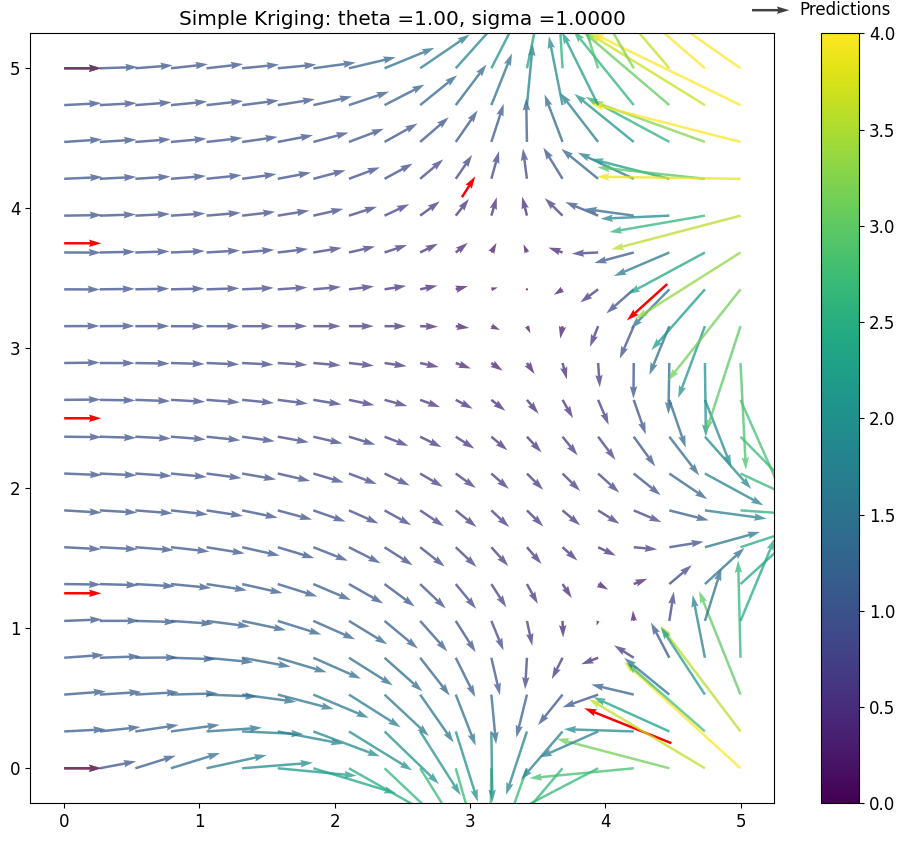

In [12]:
# Matrix U Continuity equation.
U = Umat([1,1], nd**2)                                      # 1 dfxx + 1 dfyy = 0

# kernel parameters
theta =  1.0
sigma = 1.0
params = dict(theta = theta, sigma = sigma)
CovwParams = lambda *Z: CovM(*Z, kernel = DiffKernel, **params)  

# Matrix K
K11 = CovwParams(Obs)                                       # Using the block structure to construct K.
K12 = CovwParams(Obs, D) @ U; K21 = K12.T
K22 = U.T @ CovwParams(D, D) @ U
K = np.block([[K11, K12],
                [K21, K22]])
Kinv = fnKinv(K)                                            # Inverted matrix

# Matrix H
H1 = CovwParams(Obs, Pred)
H2 = U.T @ CovwParams(D, Pred)
H = np.block([[H1],
                [H2]])

# final predictions
Zobs = np.zeros(vobs.shape[0] + nd**2)                      # Extended vector of observations. nd**2 => Laplacian = 0
Zobs[:vobs.shape[0]] = vobs
vhat = H.T @ Kinv @ Zobs                                    
vxhat = vhat[:npred**2]; 
vyhat = vhat[npred**2:];

# Visualization
visualize(vxhat, vyhat)
